<a href="https://colab.research.google.com/github/zakateryila/Zaka-Teryila-Peter-/blob/main/Copy_of_CAPSTONE_dogs%2C_cat_or_neither.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
from PIL import Image
import os
import json
import zipfile

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os

drive_path = "/content/drive/MyDrive"

for item in os.listdir(drive_path):
    print(item)


Colab Notebooks
capstone
cat_dog_neither
CatDogNeither_Model


In [ ]:

import os

folders = [
    "/content/drive/MyDrive/cat_dog_neither",
    "/content/drive/MyDrive/capstone"
]

for folder in folders:
    print("\nFOLDER:", folder)

    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            level = root.replace(folder, "").count(os.sep)
            indent = "  " * level
            print(f"{indent}{os.path.basename(root)}/")

            for file in files[:5]:
                print(f"{indent}  {file}")

            if level >= 3:
                dirs[:] = []
    else:
        print("Folder not found")



FOLDER: /content/drive/MyDrive/cat_dog_neither
cat_dog_neither/
  cat/
    cat.9975.jpg
    cat.9937.jpg
    cat.9945.jpg
    cat.996.jpg
    cat.995.jpg
  dog/
    1793023042976.jpg
    1793023045029.jpg
    1793023047135.jpg
    1793023651825.jpg
    1793023628429.jpg
  neither/
    1736537985897.jpg
    20250415_140646.heic
    20250415_140651.heic
    20250416_112219.heic
    20250416_155728.heic

FOLDER: /content/drive/MyDrive/capstone
capstone/
  own/
    dog/
    cat/
    neither/


In [ ]:

import os
from collections import Counter

dataset_path = "/content/drive/MyDrive/cat_dog_neither"

for category in ["cat", "dog", "neither"]:
    folder = os.path.join(dataset_path, category)

    files = [
        f for f in os.listdir(folder)
        if os.path.isfile(os.path.join(folder, f))
    ]

    extensions = Counter(
        os.path.splitext(f)[1].lower() for f in files
    )

    print(f"\n{category.upper()}")
    print("Total files:", len(files))
    print("File formats:", dict(extensions))



CAT
Total files: 500
File formats: {'.jpg': 500}

DOG
Total files: 459
File formats: {'.jpg': 459}

NEITHER
Total files: 139
File formats: {'.jpg': 109, '.heic': 30}


In [ ]:

!pip install -q pillow pillow-heif scikit-learn matplotlib


In [ ]:

import os
from PIL import Image
from pillow_heif import register_heif_opener

register_heif_opener()

source = "/content/drive/MyDrive/cat_dog_neither"
prepared = "/content/cat_dog_neither_ready"

os.makedirs(prepared, exist_ok=True)

for category in ["cat", "dog", "neither"]:
    src_folder = os.path.join(source, category)
    dst_folder = os.path.join(prepared, category)
    os.makedirs(dst_folder, exist_ok=True)

    converted = 0
    skipped = 0

    for filename in os.listdir(src_folder):
        src_file = os.path.join(src_folder, filename)

        if not os.path.isfile(src_file):
            continue

        try:
            with Image.open(src_file) as img:
                img = img.convert("RGB")
                new_name = os.path.splitext(filename)[0] + ".jpg"
                dst_file = os.path.join(dst_folder, new_name)
                img.save(dst_file, "JPEG", quality=95)
                converted += 1
        except Exception as e:
            skipped += 1
            print("Could not process:", filename, "|", str(e))

    print(category, "- prepared:", converted, "| skipped:", skipped)

print("\nPrepared dataset:", prepared)


cat - prepared: 500 | skipped: 0
dog - prepared: 459 | skipped: 0
neither - prepared: 139 | skipped: 0

Prepared dataset: /content/cat_dog_neither_ready


In [ ]:

import os

prepared = "/content/cat_dog_neither_ready"

for category in ["cat", "dog", "neither"]:
    folder = os.path.join(prepared, category)
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print(category, ":", len(images), "images")


cat : 500 images
dog : 459 images
neither : 139 images


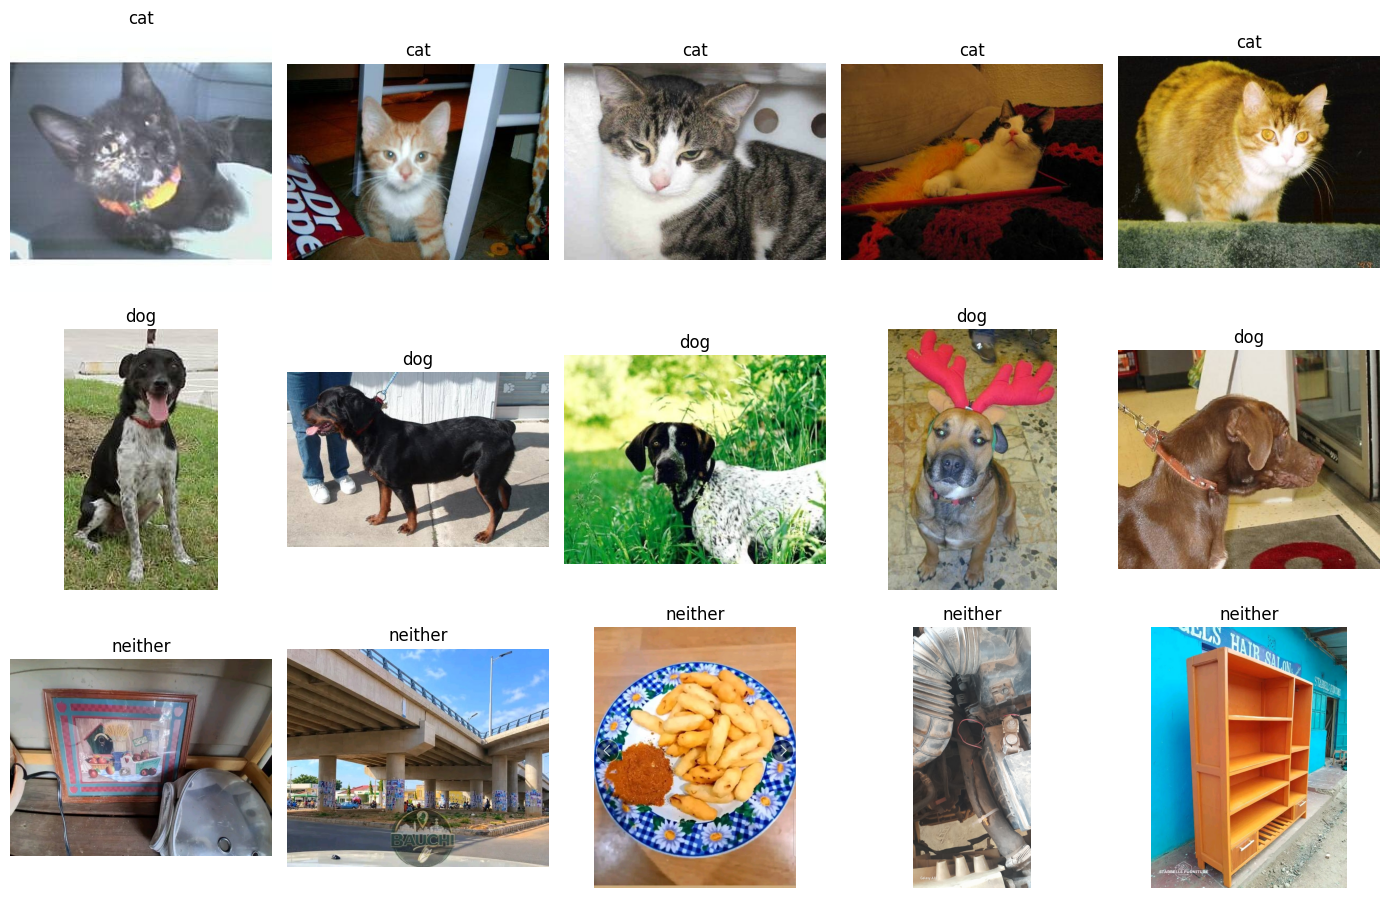

In [ ]:

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/cat_dog_neither_ready"
random.seed(42)

fig, axes = plt.subplots(3, 5, figsize=(14, 9))

for row, category in enumerate(["cat", "dog", "neither"]):
    folder = os.path.join(dataset_path, category)
    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    samples = random.sample(files, min(5, len(files)))

    for col, filename in enumerate(samples):
        path = os.path.join(folder, filename)

        with Image.open(path) as img:
            axes[row, col].imshow(img.copy())

        axes[row, col].set_title(category)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import os
import shutil
from sklearn.model_selection import train_test_split

source = "/content/cat_dog_neither_ready"
output = "/content/cat_dog_neither_split"
classes = ["cat", "dog", "neither"]

# Collect image paths and their labels
image_paths = []
labels = []

for category in classes:
    folder = os.path.join(source, category)

    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(folder, filename))
            labels.append(category)

# 70% training and 30% temporary
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Split temporary data equally into validation and testing
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

# Copy images into the new folders
for split_name, paths, split_labels in [
    ("train", train_paths, train_labels),
    ("validation", val_paths, val_labels),
    ("test", test_paths, test_labels)
]:
    for path, label in zip(paths, split_labels):
        destination = os.path.join(output, split_name, label)
        os.makedirs(destination, exist_ok=True)
        shutil.copy2(
            path,
            os.path.join(destination, os.path.basename(path))
        )

print("Dataset split completed!")

for split_name in ["train", "validation", "test"]:
    print(f"\n{split_name.upper()}")

    for category in classes:
        folder = os.path.join(output, split_name, category)
        count = len(os.listdir(folder))
        print(f"{category}: {count}")

print("\nDataset location:", output)


Dataset split completed!

TRAIN
cat: 350
dog: 321
neither: 97

VALIDATION
cat: 75
dog: 69
neither: 21

TEST
cat: 75
dog: 69
neither: 21

Dataset location: /content/cat_dog_neither_split


In [ ]:

import tensorflow as tf
import numpy as np

DATA_DIR = "/content/cat_dog_neither_split"
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR + "/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=["cat", "dog", "neither"],
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR + "/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=["cat", "dog", "neither"],
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR + "/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=["cat", "dog", "neither"],
    shuffle=False
)

class_names = ["cat", "dog", "neither"]

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("TensorFlow version:", tf.__version__)
print("Class order:", class_names)
print("Image size:", IMG_SIZE)


Found 768 files belonging to 3 classes.
Found 165 files belonging to 3 classes.
Found 165 files belonging to 3 classes.
TensorFlow version: 2.21.0
Class order: ['cat', 'dog', 'neither']
Image size: (224, 224)


In [ ]:

from tensorflow.keras import layers, Model

# Pretrained image feature extractor
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# MobileNetV2 expects pixel values scaled to [-1, 1]
x = layers.Rescaling(1.0 / 127.5, offset=-1)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(3, activation="softmax")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

if "history" in globals():
    print("Training history found!")
    print("Completed epochs:", len(history.history["accuracy"]))
else:
    print("Training history not found. We need to train the model first.")


Training history not found. We need to train the model first.


In [ ]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_cat_dog_neither.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)


Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 23s 218ms/step - accuracy: 0.8333 - loss: 0.4885 - val_accuracy: 0.9818 - val_loss: 0.1521
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.9674 - loss: 0.1292 - val_accuracy: 0.9818 - val_loss: 0.1028
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - accuracy: 0.9818 - loss: 0.0740 - val_accuracy: 0.9939 - val_loss: 0.0763
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.9948 - loss: 0.0473 - val_accuracy: 0.9939 - val_loss: 0.0602
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.9987 - loss: 0.0330 - val_accuracy: 0.9939 - val_loss: 0.0563
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9987 - loss: 0.0268 - val_accuracy: 0.9939 - val_loss: 0.0565
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - accuracy: 0.9987 - loss: 0.0231 - val_accuracy: 0.9939 - val_loss: 0.0462
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 1.0000 - loss: 0.0175 - val_accuracy: 0.9939 -

11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 397ms/step
Test accuracy: 98.79%


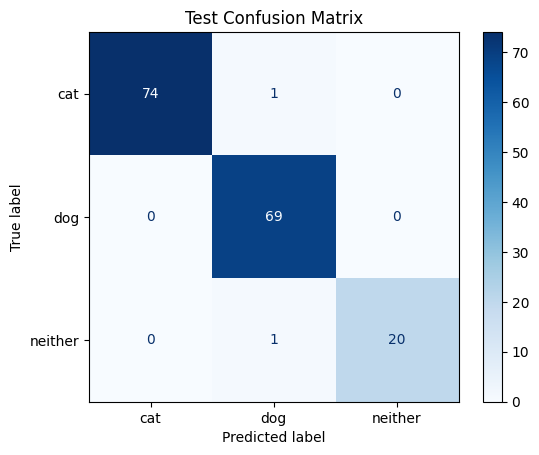


Classification report:
              precision    recall  f1-score   support

         cat       1.00      0.99      0.99        75
         dog       0.97      1.00      0.99        69
     neither       1.00      0.95      0.98        21

    accuracy                           0.99       165
   macro avg       0.99      0.98      0.98       165
weighted avg       0.99      0.99      0.99       165



In [ ]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

class_names = ["cat", "dog", "neither"]

# Load the best saved model
model = tf.keras.models.load_model(
    "/content/best_cat_dog_neither.keras"
)

# Get the true labels and predictions
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

# Overall test accuracy
test_accuracy = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

# Confusion matrix
cm = confusion_matrix(
    y_true, y_pred, labels=[0, 1, 2]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display.plot(cmap="Blues", values_format="d")
plt.title("Test Confusion Matrix")
plt.show()

# Precision, recall, F1-score
print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))


In [ ]:

import os
import json
import tensorflow as tf

save_dir = "/content/drive/MyDrive/CatDogNeither_Model"
os.makedirs(save_dir, exist_ok=True)

# Save the best trained model
model.save(os.path.join(save_dir, "cat_dog_neither.keras"))

# Save class names in the correct order
class_names = ["cat", "dog", "neither"]

with open(os.path.join(save_dir, "labels.json"), "w") as f:
    json.dump(class_names, f)

print("Model saved successfully!")
print("Location:", save_dir)
print("TensorFlow version:", tf.__version__)


Model saved successfully!
Location: /content/drive/MyDrive/CatDogNeither_Model
TensorFlow version: 2.21.0


In [ ]:

import os
import json
import zipfile

package_dir = "/content/CatDogNeither_Offline"
os.makedirs(package_dir, exist_ok=True)

# Copy the trained model and labels into the package
import shutil

shutil.copy(
    "/content/drive/MyDrive/CatDogNeither_Model/cat_dog_neither.keras",
    os.path.join(package_dir, "cat_dog_neither.keras")
)

shutil.copy(
    "/content/drive/MyDrive/CatDogNeither_Model/labels.json",
    os.path.join(package_dir, "labels.json")
)

# Create the prediction program
script = r'''
import os
import sys
import json
import csv
import numpy as np
import tensorflow as tf
from PIL import Image, ImageOps

MODEL_PATH = "cat_dog_neither.keras"
LABELS_PATH = "labels.json"
IMAGE_SIZE = (224, 224)

with open(LABELS_PATH, "r") as f:
    class_names = json.load(f)

model = tf.keras.models.load_model(MODEL_PATH)

def predict_image(path):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        image = image.resize(IMAGE_SIZE)
        array = np.asarray(image, dtype=np.float32)

    probabilities = model.predict(
        np.expand_dims(array, axis=0), verbose=0
    )[0]

    index = int(np.argmax(probabilities))
    return class_names[index], float(probabilities[index])

def main():
    if len(sys.argv) != 2:
        print("Usage: python predict_offline.py IMAGE_FOLDER")
        return

    folder = sys.argv[1]
    extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    rows = []

    for name in sorted(os.listdir(folder)):
        path = os.path.join(folder, name)

        if not os.path.isfile(path) or not name.lower().endswith(extensions):
            continue

        try:
            label, confidence = predict_image(path)
            print(
                f"{name} -> {label} "
                f"(confidence: {confidence * 100:.2f}%)"
            )
            rows.append([name, label, round(confidence * 100, 2)])
        except Exception as error:
            print(f"Could not process {name}: {error}")

    with open("predictions.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["filename", "prediction", "confidence_percent"])
        writer.writerows(rows)

    print(f"\nSaved {len(rows)} predictions to predictions.csv")

if __name__ == "__main__":
    main()
'''

with open(os.path.join(package_dir, "predict_offline.py"), "w") as f:
    f.write(script)

# Record the TensorFlow version used to save the model
with open(os.path.join(package_dir, "requirements.txt"), "w") as f:
    f.write(f"tensorflow=={tf.__version__}\n")
    f.write("numpy\n")
    f.write("Pillow\n")

# Add instructions
readme = """
CAT, DOG, OR NEITHER - OFFLINE PREDICTION

1. Install Python compatible with the TensorFlow version in requirements.txt.
2. While connected to the internet, install dependencies:
   python -m pip install -r requirements.txt
3. Create a folder named photos and place test images inside it.
4. Run:
   python predict_offline.py photos
5. Results are displayed on screen and saved to predictions.csv.

After Python and all dependencies are installed, image prediction can
run without internet. This package does not retrain the model.
"""

with open(os.path.join(package_dir, "README.txt"), "w") as f:
    f.write(readme)

zip_path = "/content/CatDogNeither_Offline.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(package_dir):
        for name in files:
            full_path = os.path.join(root, name)
            arcname = os.path.relpath(full_path, package_dir)
            z.write(full_path, arcname)

print("Offline prediction package created:", zip_path)
print("Contains model, labels, prediction script, requirements, and instructions.")


Offline prediction package created: /content/CatDogNeither_Offline.zip
Contains model, labels, prediction script, requirements, and instructions.


In [ ]:

from google.colab import files
files.download("/content/CatDogNeither_Offline.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip install -q tensorflow numpy pillow pillow-heif scikit-learn matplotlib


In [ ]:

import sys
import tensorflow as tf

print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow version: 2.21.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

model_path = "/content/drive/MyDrive/CatDogNeither_Model/cat_dog_neither.keras"

print("Model exists:", os.path.exists(model_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model exists: True


In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/CatDogNeither_Model/cat_dog_neither.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
from google.colab import files

uploaded = files.upload()

Saving cat_dog_neither.keras to cat_dog_neither.keras


In [27]:
!pip install -q gradio

In [28]:

import gradio as gr
import numpy as np
import tensorflow as tf
from PIL import Image

MODEL_PATH = "cat_dog_neither.keras"
CLASS_NAMES = ["cat", "dog", "neither"]

model = tf.keras.models.load_model(MODEL_PATH)

def predict(image):
    if image is None:
        return {}, "Please upload an image."

    image = image.convert("RGB").resize((224, 224))
    array = np.asarray(image, dtype=np.float32)
    array = np.expand_dims(array, axis=0)

    # The model already includes its rescaling layer.
    scores = model.predict(array, verbose=0)[0]

    results = {
        CLASS_NAMES[i]: float(scores[i])
        for i in range(len(CLASS_NAMES))
    }

    predicted = CLASS_NAMES[int(np.argmax(scores))]
    confidence = max(scores) * 100

    return results, (
        f"Prediction: {predicted.upper()}\n"
        f"Confidence: {confidence:.2f}%"
    )

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Upload an image"),
    outputs=[
        gr.Label(num_top_classes=3, label="Class probabilities"),
        gr.Textbox(label="Prediction result")
    ],
    title="Cat, Dog, or Neither Classifier",
    description="Upload an image to classify it as a cat, dog, or neither."
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ecbba1e8aad5058407.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
